# BÀI THỰC HÀNH 1 - BÀI 2 (TRANG 15 - 17)
## TIỀN XỬ LÝ DỮ LIỆU VỚI TẬP DỮ LIỆU TITANIC (CÂU 1 ĐẾN CÂU 8)
- **Học viên:** Nguyễn Minh Vương
- **MSSV:** 6451071090
- **Môn học:** Khai thác dữ liệu

In [8]:
# Cài đặt thư viện nếu chạy trên Google Colab
# !pip install pandas numpy matplotlib seaborn gdown

import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Tự động tải thư mục dataset từ link Google Drive
if not os.path.exists("dataset") or len(os.listdir("dataset")) == 0:
    try:
        import gdown
        drive_folder_url = "https://drive.google.com/drive/folders/1rv5SiO5zFlU-cyEXul09OpCvTXrdjG1m"
        print("Đang tải dataset từ Google Drive...")
        gdown.download_folder(drive_folder_url, output="dataset", quiet=False, use_cookies=False)
        print("✅ Tải dataset thành công!")
    except Exception as e:
        print("Lưu ý: Nếu chưa có thư viện gdown, hãy chạy lệnh: !pip install gdown")

print("Nguyễn Minh Vương - 6451071090")


Nguyễn Minh Vương - 6451071090


### Câu 1: Nhập dữ liệu và thống kê những thông tin cơ bản của các thuộc tính

In [9]:
print("Nguyễn Minh Vương - 6451071090")

df = pd.read_csv('dataset/titanic.csv', dtype={'age': np.float64, 'sibsp': np.int64, 'parch': np.int64})

print(f"Kích thước tập dữ liệu: {df.shape[0]} dòng, {df.shape[1]} cột\n")

print("--- 5 dòng đầu tiên của bảng dữ liệu ---")
display(df.head())

print("\n--- Cấu trúc và kiểu dữ liệu (info) ---")
df.info()

print("\n--- Thống kê các chỉ số định lượng (describe) ---")
display(df.describe())


Nguyễn Minh Vương - 6451071090
Kích thước tập dữ liệu: 1309 dòng, 14 cột

--- 5 dòng đầu tiên của bảng dữ liệu ---


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"



--- Cấu trúc và kiểu dữ liệu (info) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1309 non-null   int64  
 1   survived   1309 non-null   int64  
 2   name       1309 non-null   object 
 3   sex        1309 non-null   object 
 4   age        1046 non-null   float64
 5   sibsp      1309 non-null   int64  
 6   parch      1309 non-null   int64  
 7   ticket     1309 non-null   object 
 8   fare       1308 non-null   float64
 9   cabin      295 non-null    object 
 10  embarked   1307 non-null   object 
 11  boat       486 non-null    object 
 12  body       121 non-null    float64
 13  home.dest  745 non-null    object 
dtypes: float64(3), int64(4), object(7)
memory usage: 143.3+ KB

--- Thống kê các chỉ số định lượng (describe) ---


,pclass,survived,age,sibsp,parch,fare,body
count,1309.000000,1309.000000,1046.000000,1309.000000,1309.000000,1308.000000,121.000000
mean,2.294882,0.381971,29.881135,0.498854,0.385027,33.295479,160.809917
std,0.837836,0.486055,14.413500,1.041658,0.865560,51.758668,97.696922
min,1.000000,0.000000,0.166700,0.000000,0.000000,0.000000,1.000000
25%,2.000000,0.000000,21.000000,0.000000,0.000000,7.895800,72.000000
50%,3.000000,0.000000,28.000000,0.000000,0.000000,14.454200,155.000000
75%,3.000000,1.000000,39.000000,1.000000,0.000000,31.275000,256.000000
max,3.000000,1.000000,80.000000,8.000000,9.000000,512.329200,328.000000


### Câu 2: Liệt kê danh sách 5 thuộc tính có số lượng giá trị rỗng nhiều nhất

In [10]:
print("Nguyễn Minh Vương - 6451071090")

total = df.isnull().sum().sort_values(ascending=False)
percent_1 = df.isnull().sum() / df.isnull().count() * 100
percent_2 = (round(percent_1, 1)).sort_values(ascending=False)
missing_data = pd.concat([total, percent_2], axis=1, keys=['Total', '%'])

print("Top 5 thuộc tính có số lượng giá trị rỗng nhiều nhất:")
display(missing_data.head(5))


Nguyễn Minh Vương - 6451071090
Top 5 thuộc tính có số lượng giá trị rỗng nhiều nhất:


,Total,%
body,1188,90.8
cabin,1014,77.5
boat,823,62.9
home.dest,564,43.1
age,263,20.1


### Câu 3: Vẽ biểu đồ khảo sát sự liên quan giữa thuộc tính Độ tuổi (age), Giới tính (sex) và thuộc tính quyết định – khả năng sống sót (survived) và đưa ra nhận xét

Nguyễn Minh Vương - 6451071090


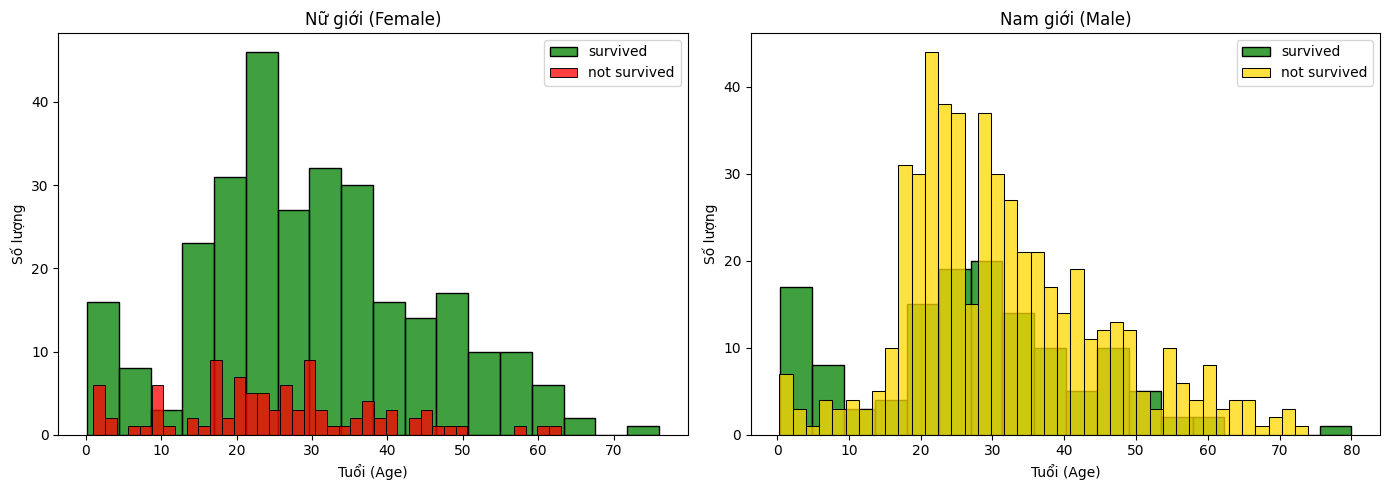

In [11]:
print("Nguyễn Minh Vương - 6451071090")

survived = 'survived'
not_survived = 'not survived'
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

women = df[df['sex'] == 'female']
men = df[df['sex'] == 'male']

# Biểu đồ cho Nữ giới
ax = sns.histplot(women[women['survived'] == 1].age.dropna(), bins=18, label=survived, ax=axes[0], kde=False, color='green')
ax = sns.histplot(women[women['survived'] == 0].age.dropna(), bins=40, label=not_survived, ax=axes[0], kde=False, color='red')
ax.legend()
ax.set_title('Nữ giới (Female)')
ax.set_xlabel('Tuổi (Age)')
ax.set_ylabel('Số lượng')

# Biểu đồ cho Nam giới
ax = sns.histplot(men[men['survived'] == 1].age.dropna(), bins=18, label=survived, ax=axes[1], kde=False, color='green')
ax = sns.histplot(men[men['survived'] == 0].age.dropna(), bins=40, label=not_survived, ax=axes[1], kde=False, color='gold')
ax.legend()
ax.set_title('Nam giới (Male)')
ax.set_xlabel('Tuổi (Age)')
ax.set_ylabel('Số lượng')

plt.tight_layout()
plt.show()


### Câu 4: Vẽ biểu đồ khảo sát sự liên quan giữa thuộc tính Cổng lên tàu (embarked) và loại vé (pclass) với khả năng sống sót (survived), phân biệt theo Giới tính (sex) và đưa ra nhận xét

Nguyễn Minh Vương - 6451071090


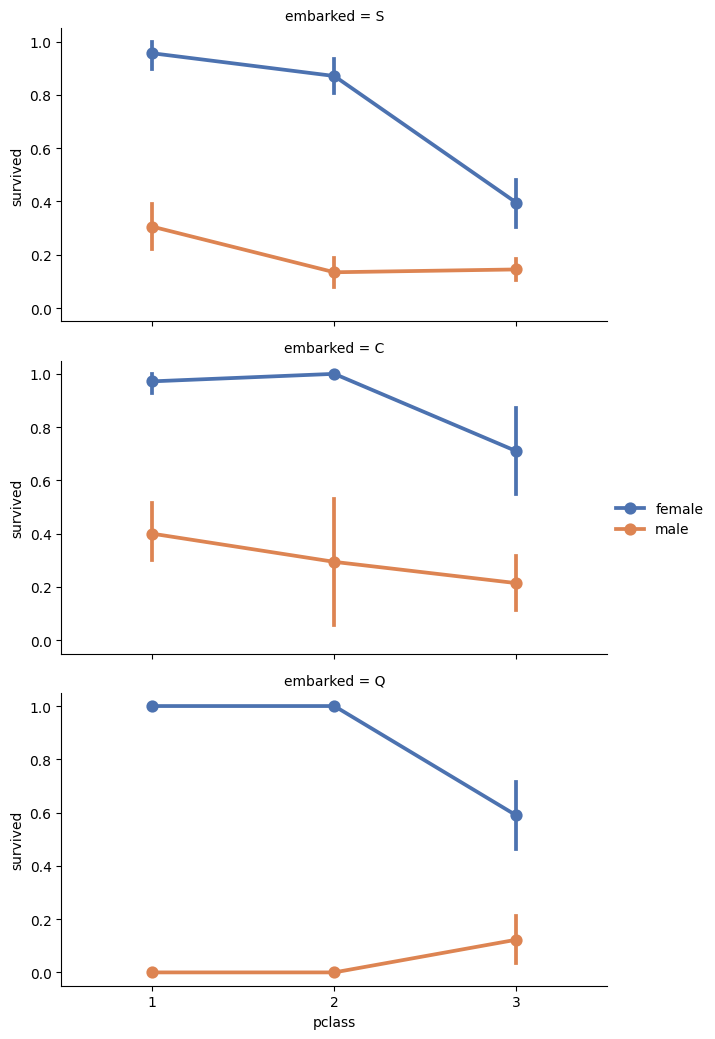

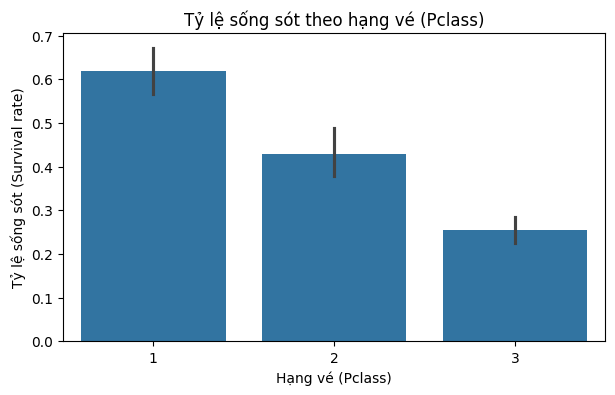

In [13]:
print("Nguyễn Minh Vương - 6451071090")

# Biểu đồ quan hệ giữa Embarked, Pclass, Sex và Survived
FacetGrid = sns.FacetGrid(df, row='embarked', height=3.5, aspect=1.8)
FacetGrid.map(sns.pointplot, 'pclass', 'survived', 'sex', palette='deep', order=[1, 2, 3], hue_order=['female', 'male'])
FacetGrid.add_legend()
plt.show()

# Biểu đồ bổ trợ: Tỷ lệ sống sót theo loại vé (Pclass)
plt.figure(figsize=(7, 4))
sns.barplot(x='pclass', y='survived', data=df)
plt.title('Tỷ lệ sống sót theo hạng vé (Pclass)')
plt.xlabel('Hạng vé (Pclass)')
plt.ylabel('Tỷ lệ sống sót (Survival rate)')
plt.show()


### Câu 5: Thống kê số người đi cùng (anh chị em/vợ chồng hoặc cha mẹ/con cái) và khảo sát sự liên quan với thuộc tính quyết định và đưa ra nhận xét

Nguyễn Minh Vương - 6451071090
Thống kê số lượng hành khách đi một mình vs đi cùng người thân:
- Số người đi một mình (1): 790 người
- Số người đi cùng người thân (0): 519 người



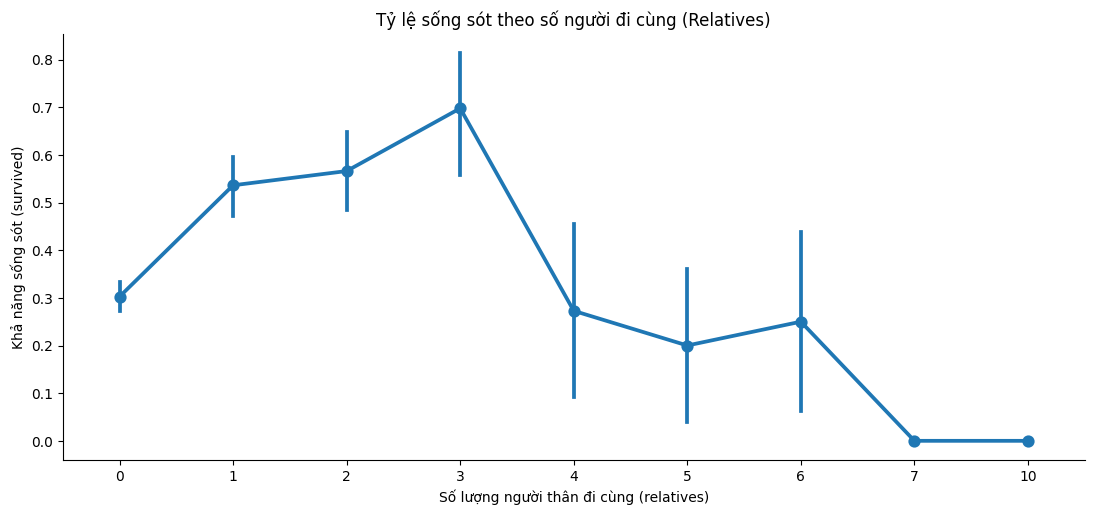

In [ ]:
print("Nguyễn Minh Vương - 6451071090")

# Tạo thuộc tính tổng số người thân: relatives = sibsp + parch
df['relatives'] = df['sibsp'] + df['parch']
df.loc[df['relatives'] > 0, 'not_alone'] = 0
df.loc[df['relatives'] == 0, 'not_alone'] = 1
df['not_alone'] = df['not_alone'].astype(int)

print("Thống kê số lượng hành khách đi một mình vs đi cùng người thân:")
counts = df['not_alone'].value_counts()
print(f"- Số người đi một mình (1): {counts[1]} người")
print(f"- Số người đi cùng người thân (0): {counts[0]} người\n")

# Vẽ biểu đồ mối quan hệ giữa relatives và survived
axes = sns.catplot(x='relatives', y='survived', data=df, aspect=2.2, kind='point')
plt.title('Tỷ lệ sống sót theo số người đi cùng (Relatives)')
plt.xlabel('Số lượng người thân đi cùng (relatives)')
plt.ylabel('Khả năng sống sót (survived)')
plt.show()


### Câu 6: Tiền xử lý các thuộc tính thiếu dữ liệu và xóa bỏ các thuộc tính không cần thiết

In [15]:
print("Nguyễn Minh Vương - 6451071090")

# 1. Trích xuất thuộc tính deck từ cabin trước khi xóa
deck = {"A": 1, "B": 2, "C": 3, "D": 4, "E": 5, "F": 6, "G": 7, "U": 8}
df['cabin'] = df['cabin'].fillna("U0")
df['deck'] = df['cabin'].map(lambda x: re.compile("([a-zA-Z]+)").search(x).group())
df['deck'] = df['deck'].map(deck)
df['deck'] = df['deck'].fillna(0).astype(int)

# 2. Xóa bỏ các thuộc tính không cần thiết (ticket, boat, body, home.dest, cabin)
df_clean = df.drop(['cabin', 'ticket', 'boat', 'body', 'home.dest'], axis=1)

# 3. Điền giá trị còn thiếu vào thuộc tính tuổi (age) bằng giá trị ngẫu nhiên dựa trên mean và std
mean = df_clean["age"].mean()
std = df_clean["age"].std()
is_null = df_clean["age"].isnull().sum()
rand_age = np.random.randint(mean - std, mean + std, size=is_null)
age_slice = df_clean["age"].copy()
age_slice[np.isnan(age_slice)] = rand_age
df_clean["age"] = age_slice.astype(int)

# 4. Điền giá trị còn thiếu vào thuộc tính Cổng lên tàu (embarked) bằng giá trị phổ biến nhất ('S')
common_value = df_clean['embarked'].mode()[0]
df_clean['embarked'] = df_clean['embarked'].fillna(common_value)

# 5. Điền giá trị thiếu cho thuộc tính giá vé (fare)
df_clean['fare'] = df_clean['fare'].fillna(df_clean['fare'].median())

print("Kiểm tra lại số lượng giá trị thiếu (null) sau khi xử lý:")
print(df_clean.isnull().sum())

print("\n5 dòng đầu tiên sau khi hoàn tất tiền xử lý:")
display(df_clean.head())


Nguyễn Minh Vương - 6451071090
Kiểm tra lại số lượng giá trị thiếu (null) sau khi xử lý:
pclass       0
survived     0
name         0
sex          0
age          0
sibsp        0
parch        0
fare         0
embarked     0
relatives    0
not_alone    0
deck         0
dtype: int64

5 dòng đầu tiên sau khi hoàn tất tiền xử lý:


,pclass,survived,name,sex,age,sibsp,parch,fare,embarked,relatives,not_alone,deck
0,1,1,"Allen, Miss. Elisabeth Walton",female,29,0,0,211.3375,S,0,1,2
1,1,1,"Allison, Master. Hudson Trevor",male,0,1,2,151.5500,S,3,0,3
2,1,0,"Allison, Miss. Helen Loraine",female,2,1,2,151.5500,S,3,0,3
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30,1,2,151.5500,S,3,0,3
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25,1,2,151.5500,S,3,0,3


### Câu 7: Biến đổi các thuộc tính: fare về số nguyên, trích xuất title từ name, mã hóa sex và embarked thành số, chia nhóm age và fare

In [16]:
print("Nguyễn Minh Vương - 6451071090")

# 1. Chuyển đổi thuộc tính giá vé (fare) về kiểu nguyên
df_clean['fare'] = df_clean['fare'].fillna(0).astype(int)

# 2. Trích xuất thuộc tính danh hiệu (title) từ tên (name) và xóa cột name
titles = {"Mr": 1, "Miss": 2, "Mrs": 3, "Master": 4, "Rare": 5}
df_clean['title'] = df_clean['name'].str.extract(' ([A-Za-z]+)\.', expand=False)
df_clean['title'] = df_clean['title'].replace(['Lady', 'Countess','Capt', 'Col','Don', 'Dr',
                                               'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona'], 'Rare')
df_clean['title'] = df_clean['title'].replace('Mlle', 'Miss')
df_clean['title'] = df_clean['title'].replace('Ms', 'Miss')
df_clean['title'] = df_clean['title'].replace('Mme', 'Mrs')
df_clean['title'] = df_clean['title'].map(titles).fillna(0).astype(int)
df_clean.drop(['name'], axis=1, inplace=True)

# 3. Chuyển đổi thuộc tính giới tính (sex) và cổng lên tàu (embarked) thành số
genders = {"male": 0, "female": 1}
df_clean['sex'] = df_clean['sex'].map(genders)

ports = {"S": 0, "C": 1, "Q": 2}
df_clean['embarked'] = df_clean['embarked'].map(ports)

# 4. Chia giá trị thuộc tính tuổi (age) thành 8 nhóm cân bằng
df_clean.loc[df_clean['age'] <= 11, 'age'] = 0
df_clean.loc[(df_clean['age'] > 11) & (df_clean['age'] <= 18), 'age'] = 1
df_clean.loc[(df_clean['age'] > 18) & (df_clean['age'] <= 22), 'age'] = 2
df_clean.loc[(df_clean['age'] > 22) & (df_clean['age'] <= 27), 'age'] = 3
df_clean.loc[(df_clean['age'] > 27) & (df_clean['age'] <= 33), 'age'] = 4
df_clean.loc[(df_clean['age'] > 33) & (df_clean['age'] <= 40), 'age'] = 5
df_clean.loc[(df_clean['age'] > 40) & (df_clean['age'] <= 66), 'age'] = 6
df_clean.loc[df_clean['age'] > 66, 'age'] = 7
df_clean['age'] = df_clean['age'].astype(int)

# 5. Chia giá trị thuộc tính giá vé (fare) thành 6 nhóm
df_clean.loc[df_clean['fare'] <= 7.91, 'fare'] = 0
df_clean.loc[(df_clean['fare'] > 7.91) & (df_clean['fare'] <= 14.454), 'fare'] = 1
df_clean.loc[(df_clean['fare'] > 14.454) & (df_clean['fare'] <= 31), 'fare'] = 2
df_clean.loc[(df_clean['fare'] > 31) & (df_clean['fare'] <= 99), 'fare'] = 3
df_clean.loc[(df_clean['fare'] > 99) & (df_clean['fare'] <= 250), 'fare'] = 4
df_clean.loc[df_clean['fare'] > 250, 'fare'] = 5
df_clean['fare'] = df_clean['fare'].astype(int)

print("Phân bố số lượng phần tử theo các nhóm tuổi (age):")
print(df_clean['age'].value_counts().sort_index())
print("\nPhân bố số lượng phần tử theo các nhóm giá vé (fare):")
print(df_clean['fare'].value_counts().sort_index())
print("\n5 dòng đầu tiên sau khi biến đổi thuộc tính:")
display(df_clean.head())


Nguyễn Minh Vương - 6451071090
Phân bố số lượng phần tử theo các nhóm tuổi (age):
age
0     91
1    145
2    176
3    210
4    238
5    194
6    246
7      9
Name: count, dtype: int64

Phân bố số lượng phần tử theo các nhóm giá vé (fare):
fare
0    360
1    313
2    325
3    227
4     67
5     17
Name: count, dtype: int64

5 dòng đầu tiên sau khi biến đổi thuộc tính:


<>:8: SyntaxWarning: invalid escape sequence '\.'
<>:8: SyntaxWarning: invalid escape sequence '\.'
/tmp/ipykernel_774/1142294323.py:8: SyntaxWarning: invalid escape sequence '\.'
  df_clean['title'] = df_clean['name'].str.extract(' ([A-Za-z]+)\.', expand=False)


,pclass,survived,sex,age,sibsp,parch,fare,embarked,relatives,not_alone,deck,title
0,1,1,1,4,0,0,4,0,0,1,2,2
1,1,1,0,0,1,2,4,0,3,0,3,4
2,1,0,1,0,1,2,4,0,3,0,3,2
3,1,0,0,4,1,2,4,0,3,0,3,1
4,1,0,1,3,1,2,4,0,3,0,3,3


### Câu 8: Tạo ra các thuộc tính mới (age_class và fare_per_person)

In [17]:
print("Nguyễn Minh Vương - 6451071090")

# 1. Thuộc tính tuổi * loại vé (age_class): tích của tuổi và loại vé
df_clean['age_class'] = df_clean['age'] * df_clean['pclass']

# 2. Thuộc tính giá vé trên mỗi người (fare_per_person): giá vé chia cho số người đi cùng (có làm trơn + 1)
df_clean['fare_per_person'] = (df_clean['fare'] / (df_clean['relatives'] + 1)).astype(int)

print("Bảng dữ liệu hoàn chỉnh sau khi tạo các thuộc tính mới (10 dòng đầu):")
display(df_clean.head(10))


Nguyễn Minh Vương - 6451071090
Bảng dữ liệu hoàn chỉnh sau khi tạo các thuộc tính mới (10 dòng đầu):


,pclass,survived,sex,age,sibsp,parch,fare,embarked,relatives,not_alone,deck,title,age_class,fare_per_person
0,1,1,1,4,0,0,4,0,0,1,2,2,4,4
1,1,1,0,0,1,2,4,0,3,0,3,4,0,1
2,1,0,1,0,1,2,4,0,3,0,3,2,0,1
3,1,0,0,4,1,2,4,0,3,0,3,1,4,1
4,1,0,1,3,1,2,4,0,3,0,3,3,3,1
5,1,1,0,6,0,0,2,0,0,1,5,1,6,2
6,1,1,1,6,1,0,3,0,1,0,4,2,6,1
7,1,0,0,5,0,0,0,0,0,1,1,1,5,0
8,1,1,1,6,2,0,3,0,2,0,3,3,6,1
9,1,0,0,7,0,0,3,1,0,1,8,1,7,3
